In [10]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles inside data/raw:")
raw_path = Path(r"C:\FactoryPulse\data\raw")

print(list(raw_path.iterdir()) if raw_path.exists() else "Folder does not exist")

Current working directory:
c:\FactoryPulse\data

Files inside data/raw:
[WindowsPath('C:/FactoryPulse/data/raw/01_data_exploration.ipynb'), WindowsPath('C:/FactoryPulse/data/raw/ai4i2020.csv')]


In [11]:
import pandas as pd
from pathlib import Path

dataset_path = Path(r"C:\FactoryPulse\data\raw\ai4i2020.csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [12]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10000
Columns: 14


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [14]:
# Missing values
print("Missing values:")
display(df.isnull().sum())

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Statistical summary
display(df.describe().T)

Missing values:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [16]:
failure_counts = df["Machine failure"].value_counts()

print(failure_counts)

failure_rate = df["Machine failure"].mean() * 100

print(f"Machine failure rate: {failure_rate:.2f}%")

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure rate: 3.39%


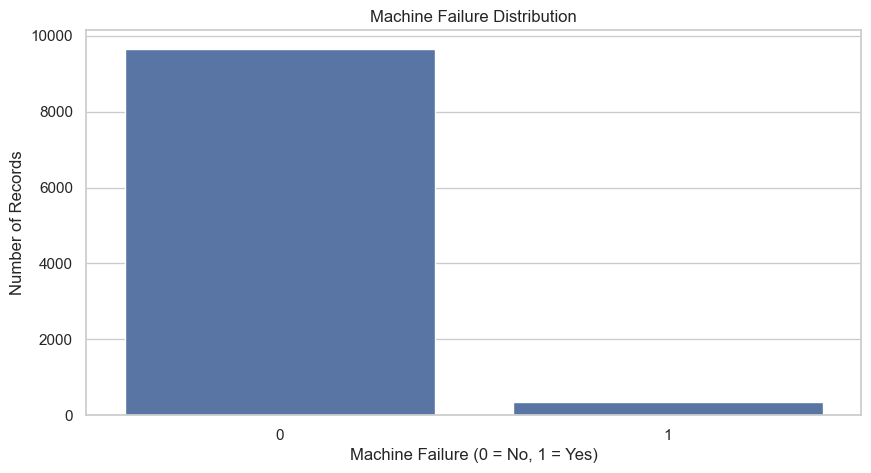

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

In [18]:

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_summary = pd.DataFrame({
    "Failure Type": failure_columns,
    "Number of Cases": [
        df[col].sum() for col in failure_columns
    ]
})

failure_summary["Percentage of Dataset"] = (
    failure_summary["Number of Cases"] / len(df) * 100
).round(2)

display(failure_summary)

,Failure Type,Number of Cases,Percentage of Dataset
0,TWF,46,0.46
1,HDF,115,1.15
2,PWF,95,0.95
3,OSF,98,0.98
4,RNF,19,0.19


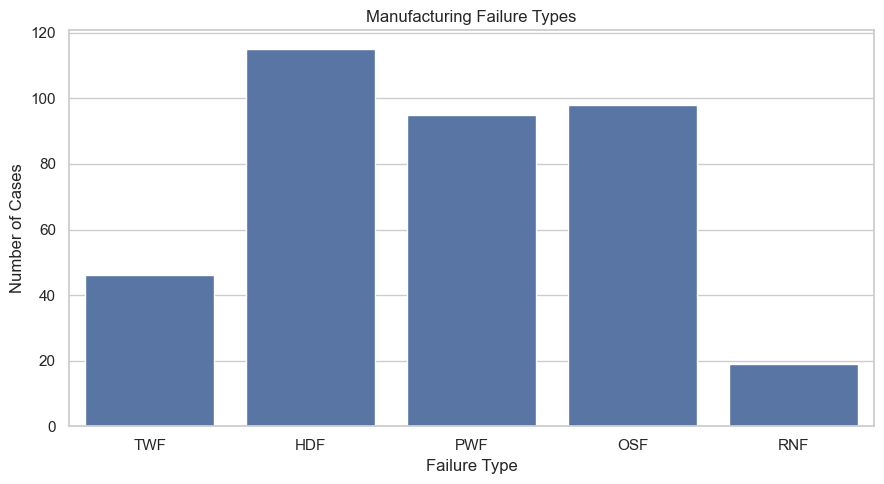

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=failure_summary,
    x="Failure Type",
    y="Number of Cases"
)

plt.title("Manufacturing Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Cases")

plt.tight_layout()
plt.show()

In [20]:

# Create a separate copy of the original dataset.
# We never modify our original raw data.

df_clean = df.copy()

# 1. Convert air temperature from Kelvin to Celsius
df_clean["Air temperature [C]"] = (
    df_clean["Air temperature [K]"] - 273.15
)

# 2. Convert process temperature from Kelvin to Celsius
df_clean["Process temperature [C]"] = (
    df_clean["Process temperature [K]"] - 273.15
)

# 3. Calculate temperature difference
df_clean["Temperature difference [C]"] = (
    df_clean["Process temperature [C]"]
    - df_clean["Air temperature [C]"]
)

# 4. Display the new features
new_features = [
    "Air temperature [C]",
    "Process temperature [C]",
    "Temperature difference [C]"
]

display(df_clean[new_features].head())

print("Feature engineering completed!")


,Air temperature [C],Process temperature [C],Temperature difference [C]
0,24.95,35.45,10.5
1,25.05,35.55,10.5
2,24.95,35.35,10.4
3,25.05,35.45,10.4
4,25.05,35.55,10.5


Feature engineering completed!


In [21]:
df_clean[
    [
        "Air temperature [C]",
        "Process temperature [C]",
        "Temperature difference [C]"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [C],10000.0,26.85493,2.000259,22.15,25.15,26.95,28.35,31.35
Process temperature [C],10000.0,36.85556,1.483734,32.55,35.65,36.95,37.95,40.65
Temperature difference [C],10000.0,10.00063,1.001094,7.60,9.30,9.80,11.00,12.10


In [22]:
print(
    "Minimum temperature difference:",
    df_clean["Temperature difference [C]"].min()
)

print(
    "Maximum temperature difference:",
    df_clean["Temperature difference [C]"].max()
)


Minimum temperature difference: 7.599999999999966
Maximum temperature difference: 12.100000000000023


In [23]:

# Convert column names into SQL-friendly names

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
)

print("New column names:")
print(df_clean.columns.tolist())


New column names:
['udi', 'product_id', 'type', 'air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf', 'air_temperature_c', 'process_temperature_c', 'temperature_difference_c']


In [24]:
from pathlib import Path

processed_path = Path(r"C:\FactoryPulse\data\processed")

processed_path.mkdir(
    parents=True,
    exist_ok=True
)

output_file = processed_path / "ai4i_processed.csv"

df_clean.to_csv(
    output_file,
    index=False
)

print("Processed dataset saved!")
print(output_file)

Processed dataset saved!
C:\FactoryPulse\data\processed\ai4i_processed.csv
